<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.2 – Word and sentence embeddings

**Objectives**
- Train Word2Vec embeddings (CBOW and Skip-gram) on your own corpus
- Use pre-trained GloVe vectors and word analogies
- Compute sentence embeddings with a BERT-based model and use them for semantic search
- Compare lexical (TF-IDF) and semantic (embeddings) similarity

**Dataset:** the same 20 Newsgroups corpus and the same 3 categories as in Lab 3.1.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. This lab downloads pre-trained models (about 250 MB in total). Google Colab is recommended on a slow connection.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, string, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import gensim
from gensim.models import Word2Vec
import gensim.downloader as api
from sklearn.metrics.pairwise import cosine_similarity

print(f"gensim {gensim.__version__} – setup complete")

gensim 4.4.0 – setup complete


## Data (same as Lab 3.1)

In [3]:
def local_file(name, lab="lab3"):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))
df = df.dropna(subset=["text"]).reset_index(drop=True)

my_categories = ["rec.sport.baseball", "rec.sport.hockey", "sci.space"]
assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Use 3 valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"{len(df_filtered)} documents in {my_categories}")

1790 documents in ['rec.sport.baseball', 'rec.sport.hockey', 'sci.space']


In [4]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_tokens(text):
    """Same cleaning as Lab 3.1, returning a list of tokens (Word2Vec expects tokenized sentences)."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stop_words and len(t) >= 3]
    return tokens

df_filtered["tokens"] = df_filtered["text"].apply(preprocess_tokens)
df_filtered["text_clean"] = df_filtered["tokens"].apply(" ".join)
corpus = df_filtered["tokens"].tolist()
print(f"Corpus: {len(corpus)} documents, {sum(len(d) for d in corpus)} tokens")
print(corpus[0][:15])

Corpus: 1790 documents, 157067 tokens
['article', 'tom', 'baker', 'understanding', 'expected', 'error', 'basically', 'known', 'bug', 'warning', 'system', 'software', 'thing', 'checked', 'right']


---
# Part A – Word2Vec: train your own embeddings

Word2Vec learns a vector per word by predicting words from their context:
- **CBOW** predicts the target word from its context words,
- **Skip-gram** predicts the context words from the target word.

In [5]:
common = dict(sentences=corpus, vector_size=100, window=5, min_count=5, workers=4, epochs=10, seed=42)
model_cbow = Word2Vec(sg=0, **common)
model_skipgram = Word2Vec(sg=1, **common)
print(f"Vocabulary size: {len(model_cbow.wv)} words")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Vocabulary size: 4874 words


In [6]:
word = "game"   # change to a word of your domain
if word in model_cbow.wv:
    print(f"Vector of '{word}': shape {model_cbow.wv[word].shape}, first values {model_cbow.wv[word][:5]}")
    print("\nMost similar (CBOW):     ", [w for w, s in model_cbow.wv.most_similar(word, topn=8)])
    print("Most similar (Skip-gram):", [w for w, s in model_skipgram.wv.most_similar(word, topn=8)])
else:
    print(f"'{word}' is not in the vocabulary. Examples:", list(model_cbow.wv.key_to_index)[:20])

Vector of 'game': shape (100,), first values [ 0.65008533 -0.3127433   0.16754544 -0.96237326 -0.46907598]

Most similar (CBOW):      ['played', 'pick', 'score', 'season', 'record', 'playoff', 'night', 'era']
Most similar (Skip-gram): ['consecutive', 'afternoon', 'tied', 'divisional', 'televised', 'victory', 'sunday', 'identical']


### Exercise A.1 – CBOW vs Skip-gram

Choose **5 domain-specific words** of your categories (not generic words such as *good* or *make*) and compare the 5 most similar words given by each model.

In [7]:
my_test_words = ["pitcher", "goalie", "playoff", "orbit", "shuttle"]

for word in my_test_words:
    word = word.lower()
    if word in model_cbow.wv:
        print(f"\n'{word}'")
        print("  CBOW:     ", [w for w, s in model_cbow.wv.most_similar(word, topn=5)])
        print("  Skip-gram:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)])
    else:
        print(f"\n'{word}' not in vocabulary")
assert sum(w.lower() in model_cbow.wv for w in my_test_words) >= 3, "At least 3 of your words must be in the vocabulary"


'pitcher'
  CBOW:      ['pitching', 'morris', 'bad', 'watch', 'brave']
  Skip-gram: ['jack', 'guzman', 'martinez', 'pitching', 'mussina']

'goalie'
  CBOW:      ['ice', 'behind', 'shutout', 'pen', 'six']
  Skip-gram: ['ketterer', 'defender', 'skater', 'fight', 'robb']

'playoff'
  CBOW:      ['played', 'regular', 'best', 'score', 'season']
  Skip-gram: ['cup', 'stanley', 'cbc', 'divisional', 'classic']

'orbit'
  CBOW:      ['earth', 'lunar', 'mar', 'surface', 'rocket']
  Skip-gram: ['circular', 'axis', 'pluto', 'inclination', 'perturbation']

'shuttle'
  CBOW:      ['program', 'commercial', 'research', 'development', 'project']
  Skip-gram: ['roll', 'liftoff', 'sts', 'landing', 'jenks']


### Question A.2 (written)

1. For which words do both models agree? For which do they differ?
2. Which model gives the better neighbours for your domain? Give examples.
3. Why can one architecture work better than the other for rare words? (think about how many training examples each word gets)

<!-- ANSWER lab3.2-A2 -->
**Your answer:**

Both models agree only partly on *pitcher*, where *pitching* appears in both lists. They differ for *goalie*, *playoff*, *orbit*, and *shuttle*, whose top 5 lists share no word.

Skip-gram gives the better neighbours for most of my words: *playoff* → *cup*, *stanley*; *shuttle* → *liftoff*, *sts*, *landing*; *orbit* → *inclination*, *perturbation*. CBOW is more general (*shuttle* → *program*, *commercial*, *research*), although *orbit* → *earth*, *lunar*, *rocket* is sensible. Neither is clean: *goalie* in Skip-gram includes the name-like *ketterer* and *robb*.

Skip-gram can work better for rare words because every occurrence of a word creates one training pair per context word, so a rare word still gets several updates. CBOW averages the context into one prediction per target, so a rare word gets fewer updates and its signal is blended with its neighbours.
<!-- END ANSWER -->

### Exercise A.3 – Analogies with your model

In [8]:
def analogy(model, a, b, c, topn=3):
    """a is to b as c is to ?   (vector arithmetic: b - a + c)"""
    try:
        return model.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
    except KeyError as e:
        return f"Word not in vocabulary: {e}"

# Try 2 analogies built from words of YOUR vocabulary
print(analogy(model_skipgram, "hockey", "nhl", "baseball"))
print(analogy(model_skipgram, "hockey", "goalie", "baseball"))

[('meaningless', 0.7036618590354919), ('reputation', 0.6918286085128784), ('statistic', 0.6860185265541077)]
[('count', 0.7609649896621704), ('opposing', 0.7430366277694702), ('comparing', 0.7391214370727539)]


### Question A.4 (written)

Did the analogies work? If yes, why does the result make sense; if not, what explains the failure (corpus size, vocabulary, frequency)?

<!-- ANSWER lab3.2-A4 -->
**Your answer:**

The analogies did not work. *hockey : nhl :: baseball : ?* returned *meaningless*, *reputation*, and *statistic*, and *hockey : goalie :: baseball : ?* returned *count*, *opposing*, and *comparing*; I expected a baseball league and a baseball position. The most likely explanation is the small corpus: only 157,067 tokens and 4,874 vocabulary words, split across three topics. Analogies need consistent relationships seen many times, and here each word pair has few examples.
<!-- END ANSWER -->

---
# Part B – Pre-trained GloVe embeddings

GloVe vectors trained on Wikipedia + Gigaword (6 billion tokens, 400 000 words, 100 dimensions). The download (about 130 MB) is cached by gensim.

In [9]:
print("Loading GloVe (first time: about 1 minute)...")
glove_model = api.load("glove-wiki-gigaword-100")
print(f"GloVe loaded: {len(glove_model.key_to_index)} words")

Loading GloVe (first time: about 1 minute)...


GloVe loaded: 400000 words


### Exercise B.1 – Your model vs GloVe

In [10]:
comparison_words = ["pitcher", "goalie", "shuttle"]

for word in comparison_words:
    word = word.lower()
    print(f"\n{'=' * 50}\n'{word}'")
    print("  Your Word2Vec:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)] if word in model_skipgram.wv else "not in vocabulary")
    print("  GloVe:        ", [w for w, s in glove_model.most_similar(word, topn=5)] if word in glove_model else "not in vocabulary")


'pitcher'
  Your Word2Vec: ['jack', 'guzman', 'martinez', 'pitching', 'mussina']
  GloVe:         ['pitchers', 'starter', 'hander', 'pitching', 'outfielder']

'goalie'
  Your Word2Vec: ['ketterer', 'defender', 'skater', 'fight', 'robb']
  GloVe:         ['goaltender', 'netminder', 'brodeur', 'defenseman', 'belfour']

'shuttle'
  Your Word2Vec: ['roll', 'liftoff', 'sts', 'landing', 'jenks']
  GloVe:         ['endeavour', 'atlantis', 'astronauts', 'nasa', 'shuttles']


### Question B.2 (written)

1. For which words is your model more relevant than GloVe? Why?
2. For which words is GloVe better? Why?
3. In a real project, when would you train your own embeddings rather than use pre-trained ones?

<!-- ANSWER lab3.2-B2 -->
**Your answer:**

My model is not clearly better overall, but it is more specific to this corpus for *pitcher* (*guzman*, *martinez*, *mussina*) and *shuttle* (*liftoff*, *sts*, *landing*), because it learned from how these forum posts talk about players and missions.

GloVe is better for all three words as general similarity: *pitcher* → *pitchers*, *starter*; *goalie* → *goaltender*, *netminder*; *shuttle* → *endeavour*, *atlantis*, *astronauts*. It was trained on about 6 billion tokens, so it has far more examples per word, while my model is noisier.

In a real project, I would train my own embeddings when the domain has specialised vocabulary or meanings that general text does not cover, and enough domain text is available. Otherwise, I would start with pre-trained vectors.
<!-- END ANSWER -->

### Exercise B.3 – Analogies with GloVe

In [11]:
print("king - man + woman =", glove_model.most_similar(positive=["king", "woman"], negative=["man"], topn=3))

# Try 3 more analogies (countries/capitals, verbs/tenses, your domain...)
print("paris - france + germany =", glove_model.most_similar(positive=["paris", "germany"], negative=["france"], topn=3))
print("walked - walk + swim =", glove_model.most_similar(positive=["walked", "swim"], negative=["walk"], topn=3))
print("puck - hockey + baseball =", glove_model.most_similar(positive=["puck", "baseball"], negative=["hockey"], topn=3))

king - man + woman = [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]
paris - france + germany = [('berlin', 0.8846380710601807), ('frankfurt', 0.7985543608665466), ('vienna', 0.76759934425354)]
walked - walk + swim = [('swam', 0.7477165460586548), ('swimming', 0.6124254465103149), ('drowned', 0.5767500400543213)]
puck - hockey + baseball = [('ball', 0.6957676410675049), ('throw', 0.6003775000572205), ('popped', 0.5974504351615906)]


---
# Part C – Sentence embeddings with a BERT-based model

`all-MiniLM-L6-v2` is a small transformer that maps a sentence (or a short document) to a 384-dimensional vector. Two texts with a similar meaning get close vectors, even without common words.

In [12]:
from sentence_transformers import SentenceTransformer
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

sample_sentences = [
    "I love programming in Python.",
    "Python is my favorite programming language.",
    "The python snake is very long.",
    "I enjoy coding and software development.",
]
embeddings = sentence_model.encode(sample_sentences)
print(f"Embeddings shape: {embeddings.shape}")

sim = cosine_similarity(embeddings)
pd.DataFrame(sim, index=[f"S{i}" for i in range(4)], columns=[f"S{i}" for i in range(4)]).round(3)

Embeddings shape: (4, 384)


,S0,S1,S2,S3
S0,1.000,0.878,0.370,0.621
S1,0.878,1.000,0.337,0.512
S2,0.370,0.337,1.000,0.058
S3,0.621,0.512,0.058,1.000


### Exercise C.1 – Document similarity with sentence embeddings

Encode 30 documents (10 per category, first 500 characters) and compute their cosine similarity matrix.

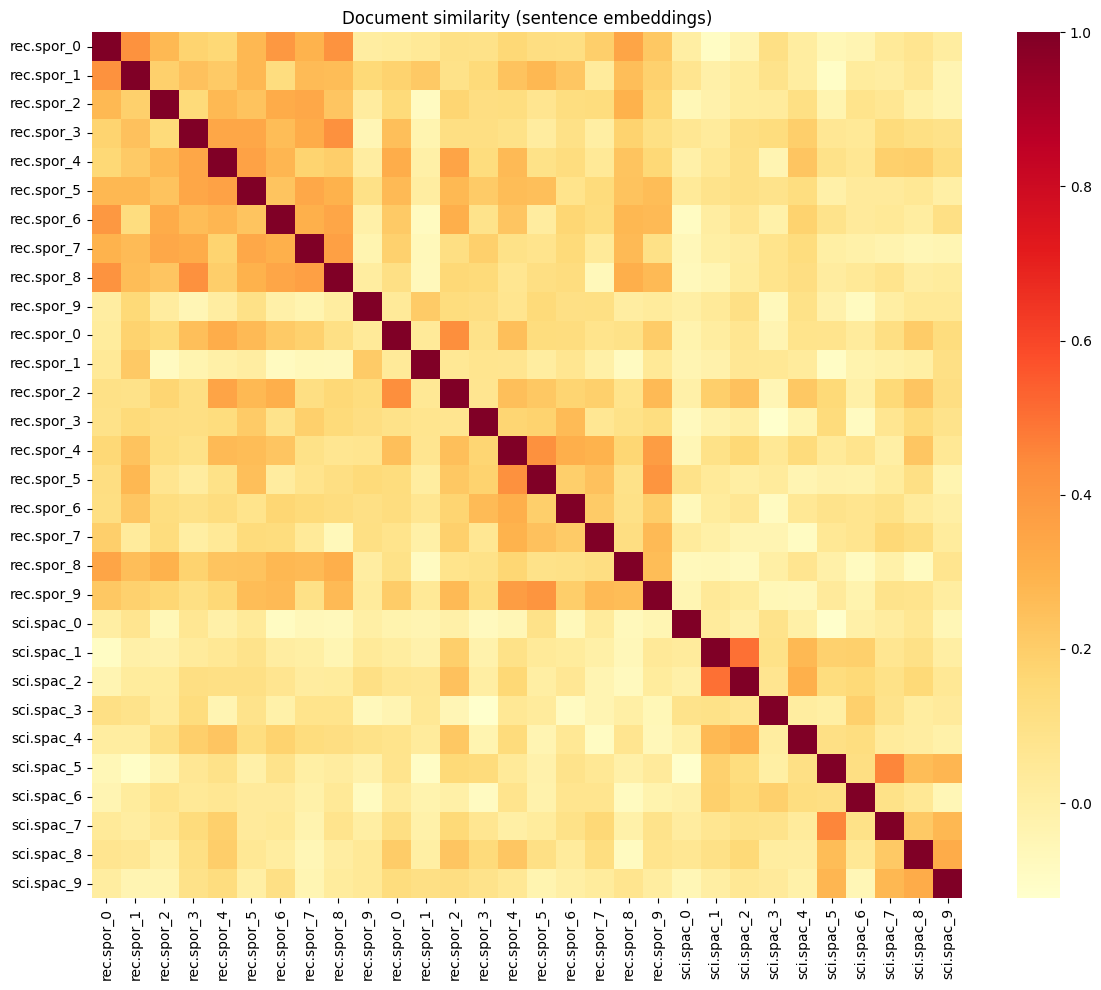

In [13]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
sampled_docs = df_sampled["text"].str[:500].tolist()
sampled_labels = df_sampled["label_text"].tolist()

doc_embeddings = sentence_model.encode(sampled_docs)
bert_similarity = cosine_similarity(doc_embeddings)

assert doc_embeddings.shape == (30, 384) and bert_similarity.shape == (30, 30)
labels = [f"{l[:8]}_{i % 10}" for i, l in enumerate(sampled_labels)]
plt.figure(figsize=(12, 10))
sns.heatmap(bert_similarity, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (sentence embeddings)")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Compare the same 30 documents with TF-IDF (same settings as the Lab 3.1 heatmap)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
tfidf_similarity = cosine_similarity(tfidf_sampled)
label_array = np.array(sampled_labels)
upper = np.triu(np.ones((30, 30), dtype=bool), k=1)

def block_mean(similarity, category_a, category_b):
    mask = upper & (((label_array[:, None] == category_a) & (label_array[None, :] == category_b)) | ((label_array[:, None] == category_b) & (label_array[None, :] == category_a)))
    return similarity[mask].mean()

for name, similarity in [("TF-IDF", tfidf_similarity), ("MiniLM", bert_similarity)]:
    print(name)
    for i, a in enumerate(my_categories):
        for b in my_categories[i:]:
            print(f"  {a} / {b}: {block_mean(similarity, a, b):.3f}")
    same = label_array[:, None] == label_array[None, :]
    print(f"  all within: {similarity[upper & same].mean():.3f}, all between: {similarity[upper & ~same].mean():.3f}")

# Pairs ranked very differently by the two methods
pairs = np.argwhere(upper)
tfidf_rank = tfidf_similarity[upper].argsort().argsort()
bert_rank = bert_similarity[upper].argsort().argsort()
for title, order in [("Higher with MiniLM", np.argmax(bert_rank - tfidf_rank)), ("Higher with TF-IDF", np.argmax(tfidf_rank - bert_rank))]:
    a, b = pairs[order]
    print(f"\n{title}: rows {a + 1} and {b + 1} ({sampled_labels[a]} / {sampled_labels[b]}), TF-IDF={tfidf_similarity[a, b]:.3f}, MiniLM={bert_similarity[a, b]:.3f}")
    print("  " + sampled_docs[a][:120].replace("\n", " "))
    print("  " + sampled_docs[b][:120].replace("\n", " "))


TF-IDF
  rec.sport.baseball / rec.sport.baseball: 0.058
  rec.sport.baseball / rec.sport.hockey: 0.045
  rec.sport.baseball / sci.space: 0.025
  rec.sport.hockey / rec.sport.hockey: 0.051
  rec.sport.hockey / sci.space: 0.022
  sci.space / sci.space: 0.035
  all within: 0.048, all between: 0.031
MiniLM
  rec.sport.baseball / rec.sport.baseball: 0.230
  rec.sport.baseball / rec.sport.hockey: 0.142
  rec.sport.baseball / sci.space: 0.040
  rec.sport.hockey / rec.sport.hockey: 0.168
  rec.sport.hockey / sci.space: 0.036
  sci.space / sci.space: 0.112
  all within: 0.170, all between: 0.073

Higher with MiniLM: rows 7 and 9 (rec.sport.baseball / rec.sport.baseball), TF-IDF=0.000, MiniLM=0.343
     Avery was the #2 overall pick by the Braves, behind Mark Lewis (I think) in 1988.  John Smoltz came over to the Brave
  Don't knock Vaughn for being a spring training .400 hitter but a .250 regular season hitter. Around 30 games played isn'

Higher with TF-IDF: rows 18 and 25 (rec.sport.hockey / 

### Question C.2 (written)

Compare with the TF-IDF heatmap of Lab 3.1 (same 30 documents):
1. Which representation groups documents of the same category better?
2. Are there documents judged similar by one method and not by the other? Why?
3. Which representation would you use for document classification? Why?

<!-- ANSWER lab3.2-C2 -->
**Your answer:**

MiniLM groups the categories better. In the comparison cell above, the mean within-category similarity is 0.170 against 0.073 between categories; for TF-IDF it is 0.048 against 0.031. Baseball–hockey is still the closest category pair (MiniLM 0.142, TF-IDF 0.045). The inputs differ slightly: MiniLM reads the first 500 characters of the raw text, and TF-IDF reads the full cleaned text.

Yes, the methods disagree on some documents. Rows 7 and 9 are both baseball posts with TF-IDF similarity 0.000 but MiniLM 0.343: they share no retained vocabulary in the TF-IDF features, but both discuss baseball players. Rows 18 (hockey) and 25 (space) have TF-IDF 0.101 but MiniLM -0.091: they share some words, but their subjects differ.

I would use sentence embeddings for classification on these categories because they separate them better here, especially with little text. This comes from 30 documents only, so I would confirm it with a classifier evaluated on a held-out test set.
<!-- END ANSWER -->

### Exercise C.3 – Semantic search

In [15]:
def semantic_search(query, documents, doc_embeddings, model, top_k=5):
    """Return the top_k (index, score) pairs of the documents closest to the query."""
    query_embedding = model.encode([query])
    scores = cosine_similarity(query_embedding, doc_embeddings).ravel()
    top_indices = np.argsort(scores)[::-1][:top_k]
    return [(int(i), float(scores[i])) for i in top_indices]

my_query = "rocket launch into orbit"

results = semantic_search(my_query, sampled_docs, doc_embeddings, sentence_model, top_k=5)
assert len(results) == 5 and all(0 <= i < 30 for i, _ in results)
print(f"Query: '{my_query}'")
for idx, score in results:
    print(f"\n  score {score:.3f} | {sampled_labels[idx]}")
    print("  " + sampled_docs[idx][:150].replace("\n", " "))

# A query that could match two of the categories (baseball and hockey)
two_category_query = "which team won the game last night"
print(f"\nQuery: '{two_category_query}'")
for idx, score in semantic_search(two_category_query, sampled_docs, doc_embeddings, sentence_model, top_k=5):
    print(f"\n  score {score:.3f} | {sampled_labels[idx]}")
    print("  " + sampled_docs[idx][:150].replace("\n", " "))


Query: 'rocket launch into orbit'

  score 0.248 | sci.space
  From another space forum     When workers at the Kennedy Space Center disassembled the STS-56  solid rocket boosters they were surprised to find a pai

  score 0.173 | sci.space
   Lets hear it for Dan Goldin...now if he can only convince the rest of our federal government that the space program is a worth while investment!  I h

  score 0.121 | sci.space
  I am doing a political science paper on the funding of NASA and pork-barrel  politics.  I would be interested in information about funding practices a

  score 0.101 | sci.space
   There was a recession, and none of the potential entrants could raise any money.  The race organizers were actually supposed to be handling part of t

  score 0.081 | sci.space
   I believe the reason is that the lung diaphram gets too tired to pump the liquid in and out and simply stops breathing after 2-3 minutes. So if your 

Query: 'which team won the game last night'

  score 0.434 | rec.

### Question C.4 (written)

1. Are the results relevant to the query?
2. Do they come from the expected category?
3. Try a query that could match two of your categories: what happens?

<!-- ANSWER lab3.2-C4 -->
**Your answer:**

For *rocket launch into orbit*, the results are partly relevant. The best result (score 0.248) discusses solid rocket boosters, while the lower ones cover human spaceflight, NASA funding, and fundraising for a race; the fifth (0.081) discusses breathing liquid and is only weakly related. All five come from the expected *sci.space* category, but the search covers only 30 documents, 10 of them about space, and the scores are low.

For *which team won the game last night*, which could match baseball or hockey, all five results come from *rec.sport.hockey*, with no baseball post. The top result (0.434) is a game report, but the fifth is a request about a playoff-stats mailing list. So the query does not return a mix of the two sports here, and the model ranks by closeness of meaning rather than balancing categories.
<!-- END ANSWER -->

---
# Part D – Visualizing embeddings with t-SNE

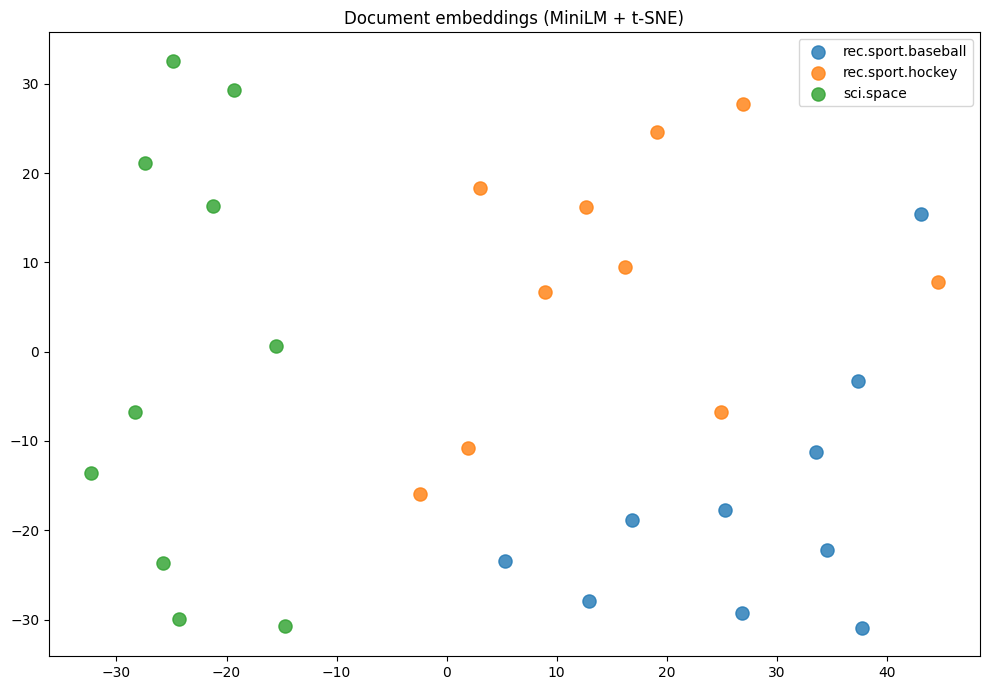

In [16]:
from sklearn.manifold import TSNE

embeddings_2d = TSNE(n_components=2, random_state=42, perplexity=10).fit_transform(doc_embeddings)
plt.figure(figsize=(10, 7))
for category in my_categories:
    mask = np.array(sampled_labels) == category
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], label=category, s=90, alpha=0.8)
plt.legend()
plt.title("Document embeddings (MiniLM + t-SNE)")
plt.tight_layout()
plt.show()

### Question D.1 (written)

1. Do the categories form distinct clusters?
2. Are there documents in the "wrong" cluster? What could explain it?
3. Which two categories are the closest? Does it match Lab 3.1?

<!-- ANSWER lab3.2-D1 -->
**Your answer:**

The categories form three visible groups, with *sci.space* clearly separate on the left. Baseball (lower right) and hockey (upper middle) are adjacent and less sharply separated.

A few points sit near the wrong group: one baseball document and one hockey document are next to each other at the far right, and some hockey documents lie near the baseball group at the bottom. This could be explained by shared sports vocabulary or by short excerpts with little topic content, although I did not check these documents individually.

Baseball and hockey are the closest categories. This matches Lab 3.1, where baseball–hockey was also the most similar pair. With 30 points, t-SNE is only a rough picture, and distances between groups should not be over-interpreted.
<!-- END ANSWER -->

---
# Part E – Final comparison

### Question E.1 (written)

1. Fill in the table.

| Method | Strengths | Weaknesses | Best use case |
|--------|-----------|------------|---------------|
| BoW | | | |
| TF-IDF | | | |
| Word2Vec (own corpus) | | | |
| GloVe | | | |
| Sentence embeddings (MiniLM) | | | |

2. For your categories, which method worked best overall? Support the answer with results from Labs 3.1 and 3.2.
3. For a real classification system on these categories, which representation would you choose and why?

<!-- ANSWER lab3.2-E1 -->
**Your answer:**

| Method | Strengths | Weaknesses | Best use case |
|--------|-----------|------------|---------------|
| BoW | Simple, fast, interpretable | Ignores order; common words dominate; high-dimensional and sparse | Baseline on clean text |
| TF-IDF | Down-weights widely shared words; interpretable; fast | No semantics; no match between synonyms; needs shared words | Baseline classification, keyword search |
| Word2Vec (own corpus) | Learns corpus-specific usage | Needs a lot of text; noisy here; failed my analogies | Large domain-specific corpora |
| GloVe | Broad vocabulary; good general similarity and analogies | General rather than domain-specific; word-level only | Word similarity, small datasets, general text |
| Sentence embeddings (MiniLM) | Compares meaning across a whole text; works without shared words | Larger model; slower; less interpretable | Semantic search, clustering, classification |

For my categories, sentence embeddings worked best overall. Their within/between means (0.170/0.073) separate the categories more than TF-IDF on the same 30 documents (0.048/0.031), semantic search returned five *sci.space* documents for a space query, and t-SNE shows three visible groups. In Lab 3.1, TF-IDF surfaced some topic words but kept generic ones such as *would* and *like*.

For a real classification system, I would choose sentence embeddings with a simple classifier such as logistic regression, because the main difficulty is separating baseball from hockey and semantic embeddings separated them better here. I would compare it with a TF-IDF baseline on a held-out test set first, since my evidence comes from small samples and no classifier was trained in this lab.
<!-- END ANSWER -->

---
## Summary

- Word2Vec learns word vectors from your corpus; CBOW and Skip-gram differ in what they predict.
- Pre-trained vectors (GloVe) cover a large general vocabulary and support analogies.
- Sentence-transformer models embed whole texts and enable semantic search without shared words.
- t-SNE projects embeddings in 2-D to inspect how documents group together.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.